In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import numpy as np
import matplotlib.pyplot as plt

print("NumPy version:", np.__version__)
print("Setup successful!")

NumPy version: 2.1.3
Setup successful!


In [3]:
import urllib.request

url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
urllib.request.urlretrieve(url, "/kaggle/working/mnist.npz")

print("Dataset downloaded!")

Dataset downloaded!


In [4]:
data = np.load("/kaggle/working/mnist.npz")

X_train = data["x_train"].reshape(-1, 784) / 255.0
y_train = data["y_train"]

X_test = data["x_test"].reshape(-1, 784) / 255.0
y_test = data["y_test"]

print("Train:", X_train.shape)
print("Test :", X_test.shape)

Train: (60000, 784)
Test : (10000, 784)


In [5]:
np.random.seed(42)

W1 = np.random.randn(784, 128) * np.sqrt(2 / 784)
b1 = np.zeros((1, 128))

W2 = np.random.randn(128, 10) * np.sqrt(2 / 128)
b2 = np.zeros((1, 10))

print("Network initialized!")

Network initialized!


In [6]:
def relu(x):
    return np.maximum(0, x)

def softmax(x):
    exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
    return exp_x / np.sum(exp_x, axis=1, keepdims=True)

def forward(X):
    Z1 = X @ W1 + b1
    A1 = relu(Z1)

    Z2 = A1 @ W2 + b2
    A2 = softmax(Z2)

    return Z1, A1, Z2, A2

print("Forward propagation ready!")

Forward propagation ready!


In [7]:
def loss_fn(y, probs):
    m = y.shape[0]
    return -np.mean(np.log(probs[np.arange(m), y] + 1e-8))

def backward(X, y, Z1, A1, probs):
    m = X.shape[0]

    dZ2 = probs.copy()
    dZ2[np.arange(m), y] -= 1
    dZ2 /= m

    dW2 = A1.T @ dZ2
    db2 = np.sum(dZ2, axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (Z1 > 0)

    dW1 = X.T @ dZ1
    db1 = np.sum(dZ1, axis=0, keepdims=True)

    return dW1, db1, dW2, db2

print("Loss and backpropagation ready!")

Loss and backpropagation ready!


In [8]:
lr = 0.01
epochs = 10
batch_size = 128

losses = []

for epoch in range(epochs):
    idx = np.random.permutation(len(X_train))
    X_train = X_train[idx]
    y_train = y_train[idx]

    epoch_loss = 0

    for i in range(0, len(X_train), batch_size):
        Xb = X_train[i:i+batch_size]
        yb = y_train[i:i+batch_size]

        Z1, A1, Z2, probs = forward(Xb)
        loss = loss_fn(yb, probs)

        dW1, db1, dW2, db2 = backward(
            Xb, yb, Z1, A1, probs
        )

        W1[:] -= lr * dW1
        b1[:] -= lr * db1
        W2[:] -= lr * dW2
        b2[:] -= lr * db2

        epoch_loss += loss

    avg_loss = epoch_loss / (len(X_train) // batch_size)
    losses.append(avg_loss)

    print(f"Epoch {epoch+1}/{epochs} - Loss: {avg_loss:.4f}")

Epoch 1/10 - Loss: 1.2079
Epoch 2/10 - Loss: 0.5582
Epoch 3/10 - Loss: 0.4425
Epoch 4/10 - Loss: 0.3921
Epoch 5/10 - Loss: 0.3619
Epoch 6/10 - Loss: 0.3408
Epoch 7/10 - Loss: 0.3245
Epoch 8/10 - Loss: 0.3111
Epoch 9/10 - Loss: 0.3001
Epoch 10/10 - Loss: 0.2903


In [9]:
_, _, _, probs = forward(X_test)

predictions = np.argmax(probs, axis=1)
accuracy = np.mean(predictions == y_test)

print(f"Test Accuracy: {accuracy * 100:.2f}%")

Test Accuracy: 92.37%


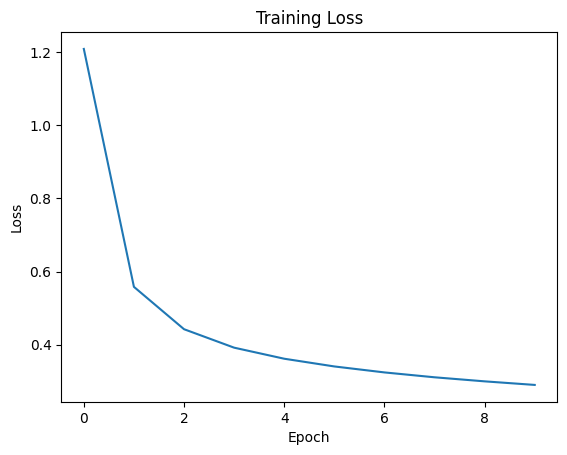

In [10]:
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training Loss")
plt.show()

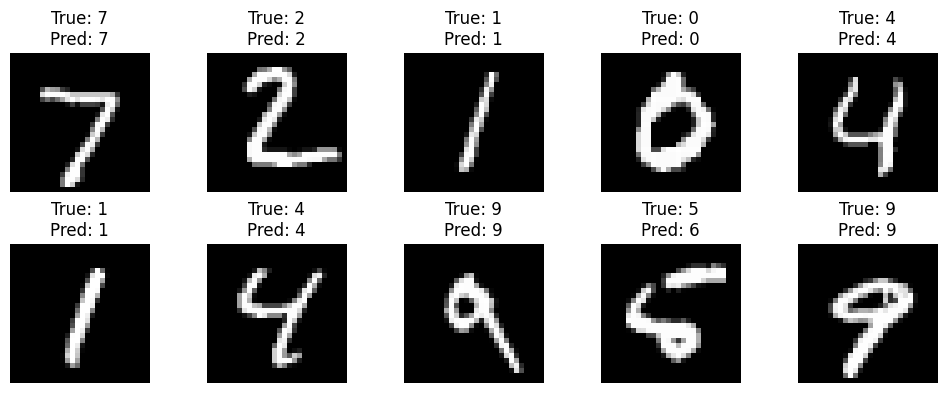

In [11]:
plt.figure(figsize=(10, 4))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_test[i].reshape(28, 28), cmap="gray")
    plt.title(f"True: {y_test[i]}\nPred: {predictions[i]}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
print("===== FINAL RESULTS =====")
print(f"Training Epochs : {epochs}")
print(f"Final Loss      : {losses[-1]:.4f}")
print(f"Test Accuracy   : {accuracy * 100:.2f}%")

===== FINAL RESULTS =====
Training Epochs : 10
Final Loss      : 0.2903
Test Accuracy   : 92.37%


In [15]:
print("Basic Neural Network From Scratch")
print("Objective: Classify handwritten digits using NumPy.")
print("Architecture: 784 -> 128 -> 10")
print("Final Test Accuracy: 92.37%")

Basic Neural Network From Scratch
Objective: Classify handwritten digits using NumPy.
Architecture: 784 -> 128 -> 10
Final Test Accuracy: 92.37%


In [16]:
print("===== CONCLUSION =====")
print("The neural network successfully learned to classify handwritten digits.")
print("The model achieved 92.37% test accuracy after 10 epochs.")
print("The complete neural network was implemented using NumPy from scratch.")

===== CONCLUSION =====
The neural network successfully learned to classify handwritten digits.
The model achieved 92.37% test accuracy after 10 epochs.
The complete neural network was implemented using NumPy from scratch.
